In [24]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
pd.set_option("display.max_rows", None, "display.max_columns", None)  
## for convenience
#import pims
import trackpy as tp


In [25]:
trajectories1 = pd.read_csv(r'/Users/rayyan/Desktop/honors_indep_study/Data/Results.csv')
#trajectories2 = trajectories1[trajectories1['frame_x'] >2000]
a = trajectories1['Slice'].max()
print(a)
print(trajectories1.head())

401
      Area  Mean  Min  Max        X      Y       XM     YM  Slice
0  1    76   255  255  255    8.605  3.263    8.605  3.263      1
1  2    72   255  255  255  368.861  3.139  368.861  3.139      1
2  3   118   255  255  255  537.373  5.407  537.373  5.407      1
3  4   127   255  255  255  611.539  5.823  611.539  5.823      1
4  5    51   255  255  255  702.402  2.480  702.402  2.480      1


Particles in frame 51 : 2738


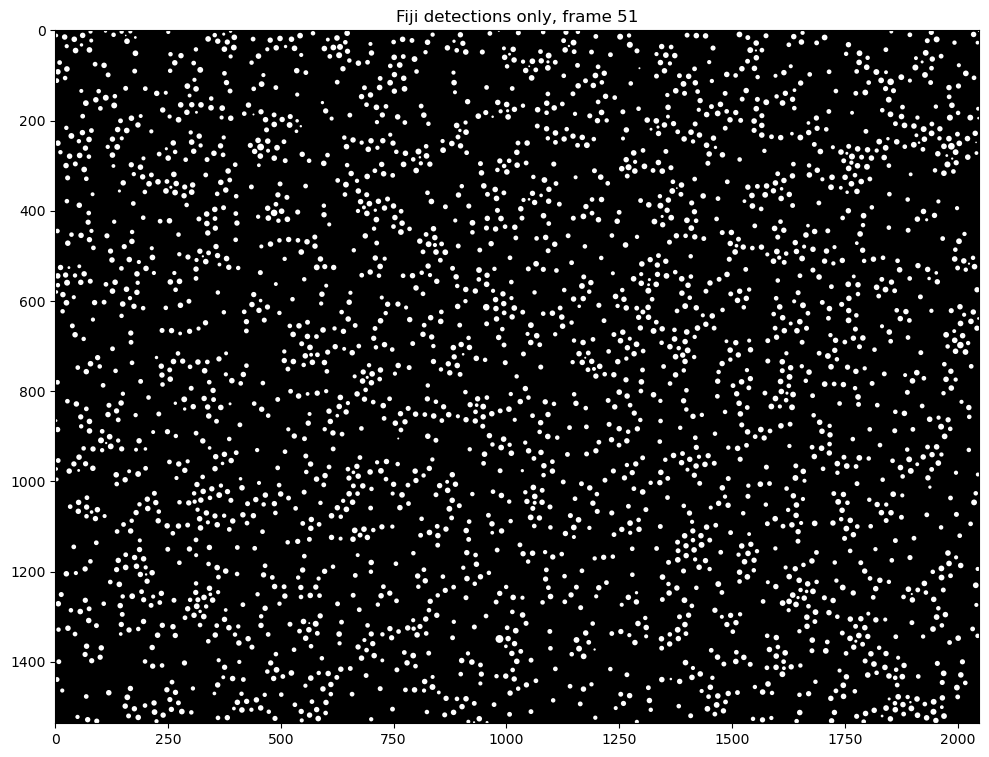

In [26]:
from matplotlib.patches import Circle
from matplotlib.collections import PatchCollection

frame_num = 51
f51 = trajectories1[trajectories1['Slice'] == frame_num]   # 'Slice' is the frame number
print("Particles in frame", frame_num, ":", len(f51))

fig, ax = plt.subplots(figsize=(12, 9))
ax.set_facecolor('black')

# one disk per particle; area = pi*r^2, so r = sqrt(Area/pi)
disks = [Circle((x, y), np.sqrt(a / np.pi))
         for x, y, a in zip(f51['X'], f51['Y'], f51['Area'])]
ax.add_collection(PatchCollection(disks, facecolor='white', edgecolor='none'))

ax.set_xlim(0, 2048)
ax.set_ylim(1536, 0)        # flipped so y runs downward like the image
ax.set_aspect('equal')
ax.set_title(f'Fiji detections only, frame {frame_num}')
plt.show()

Fiji detections in frame 51 : 2738
Image shape: (1536, 2048)


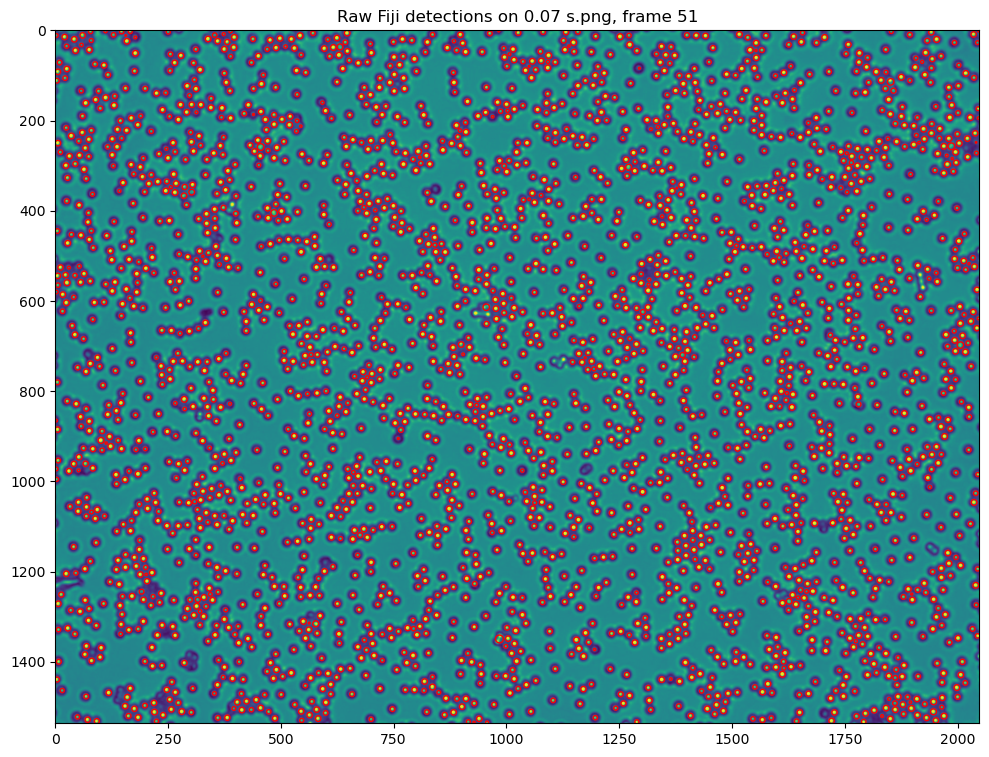

In [27]:
from matplotlib.patches import Circle
from matplotlib.collections import PatchCollection

frame_num = 51
f51 = trajectories1[trajectories1['Slice'] == frame_num]
print("Fiji detections in frame", frame_num, ":", len(f51))

img = plt.imread(r'/Users/rayyan/Desktop/honors_indep_study/0.07 s.png')
print("Image shape:", img.shape)

# full frame: XLIM, YLIM = (0, 2048), (1536, 0)
# zoomed on the cluster we looked at before: (1600, 1690), (1010, 900)
XLIM, YLIM = (0, 2048), (1536, 0)

fig, ax = plt.subplots(figsize=(12, 9))
ax.imshow(img)

rings = [Circle((x, y), np.sqrt(a / np.pi))
         for x, y, a in zip(f51['X'], f51['Y'], f51['Area'])]
ax.add_collection(PatchCollection(rings, facecolor='none', edgecolor='red', linewidth=1))

ax.set_xlim(*XLIM)
ax.set_ylim(*YLIM)
ax.set_title(f'Raw Fiji detections on 0.07 s.png, frame {frame_num}')
plt.show()
# checking if results are accurate by superimposing a frame onto the actual data file

In [28]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", None, "display.max_columns", None)

import trackpy as tp

trajectories1 = pd.read_csv(
    r'/Users/rayyan/Desktop/honors_indep_study/Data/Results.csv'
)

print("Columns:")
print(trajectories1.columns)

print("\nFirst few rows:")
print(trajectories1.head())

print("\nShape:")
print(trajectories1.shape)

print("\nSlice/frame range:")
print("min Slice:", trajectories1['Slice'].min())
print("max Slice:", trajectories1['Slice'].max())

print("\nCoordinate ranges:")
print("x min/max:", trajectories1['X'].min(), trajectories1['X'].max())
print("y min/max:", trajectories1['Y'].min(), trajectories1['Y'].max())

Columns:
Index([' ', 'Area', 'Mean', 'Min', 'Max', 'X', 'Y', 'XM', 'YM', 'Slice'], dtype='object')

First few rows:
      Area  Mean  Min  Max        X      Y       XM     YM  Slice
0  1    76   255  255  255    8.605  3.263    8.605  3.263      1
1  2    72   255  255  255  368.861  3.139  368.861  3.139      1
2  3   118   255  255  255  537.373  5.407  537.373  5.407      1
3  4   127   255  255  255  611.539  5.823  611.539  5.823      1
4  5    51   255  255  255  702.402  2.480  702.402  2.480      1

Shape:
(1102382, 10)

Slice/frame range:
min Slice: 1
max Slice: 401

Coordinate ranges:
x min/max: 0.955 2047.045
y min/max: 0.9 1535.1


In [29]:
# Getting rid of unneeded columns 
trajectories = trajectories1.filter(items = ['X', 'Y','Area','Slice'])

# Putting in trackpy format
trajectories.columns= ['x', 'y','Area','frame']

In [30]:
t = tp.link(trajectories, 10)
t.head()

Frame 401: 2700 trajectories present.


,x,y,Area,frame,particle
0,8.605,3.263,76,1,0
1840,782.011,1010.800,90,1,1
1841,426.450,1012.742,120,1,2
1842,119.818,1014.609,110,1,3
1843,447.027,1013.581,74,1,4


In [31]:

df1 = t.filter(items = ['x', 'y','Area','frame','particle'])
df1.columns= ['x', 'y','Area','frame','particle_id']


In [32]:
# Assuming df is your trajectory dataframe
# Sort the dataframe by 'particle_id' and 'frame'
df1 = df1.sort_values(by=['particle_id', 'frame'])

# Calculate the consecutive frame differences
df1['frame_diff'] = df1.groupby('particle_id')['frame'].diff()

# Find particles with less than 5 consecutive frames
filtered_ids = df1[df1['frame_diff'] >= 5]['particle_id'].unique()

# Remove rows with particle_ids having less than 5 consecutive frames
df_filtered = df1[~df1['particle_id'].isin(filtered_ids)]

# Drop the temporary 'frame_diff' column
df_filtered = df_filtered.drop(columns=['frame_diff'])
df = df_filtered

# Now df_filtered contains the information you need

In [33]:
df.to_csv(r'/Users/rayyan/Desktop/honors_indep_study/Data/linked result.csv')

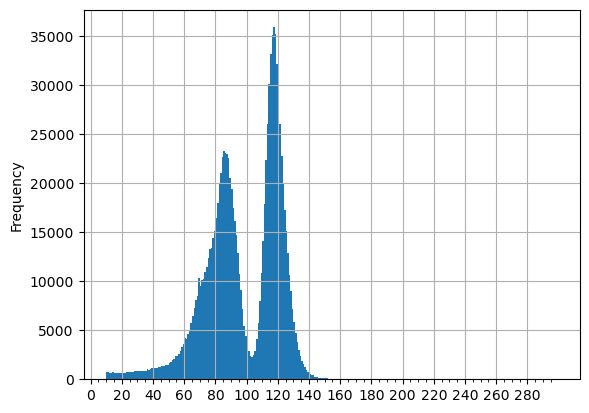

In [34]:
df=pd.read_csv(r'/Users/rayyan/Desktop/honors_indep_study/Data/linked result.csv')

ax=df.plot(kind='hist',column='Area', by=None, grid=True,  ax=None, sharex=False, sharey=False, figsize=None, layout=None, bins=range(10,300,1), backend=None, legend=False)
# Major ticks every 20, minor ticks every 5
major_ticks = np.arange(0, 300, 20)
minor_ticks = np.arange(0, 300, 5)

ax.set_xticks(major_ticks)
ax.set_xticks(minor_ticks, minor=True)
plt.show()


In [39]:
from scipy.stats import gaussian_kde
from scipy.signal import argrelextrema

areas = df['Area'].values
kde = gaussian_kde(areas)
x = np.linspace(areas.min(), areas.max(), 2000)
density = kde(x)

# the two tallest peaks, then the lowest point between them
peak_idx = argrelextrema(density, np.greater)[0]
top2 = sorted(peak_idx[np.argsort(density[peak_idx])[-2:]])
between = slice(top2[0], top2[1])
cutoff = x[between][np.argmin(density[between])]

print("Peaks at Area:", x[top2[0]], "and", x[top2[1]])
print("Cutoff (valley between them):", cutoff)

Peaks at Area: 85.85792896448224 and 116.98349174587294
Cutoff (valley between them): 102.69634817408705


In [40]:
df3 = df[df['Area'] >= 103]
df4 = df[df['Area'] < 103]

In [41]:
df3.to_csv(r'/Users/rayyan/Desktop/honors_indep_study/Data/linked result passive.csv')
df4.to_csv(r'/Users/rayyan/Desktop/honors_indep_study/Data/linked result active.csv')

In [37]:
# this code links particles from each frame so we know that between frames one particle is the same just moving.
# the graph shows a drop and a steep high because of the passive particles

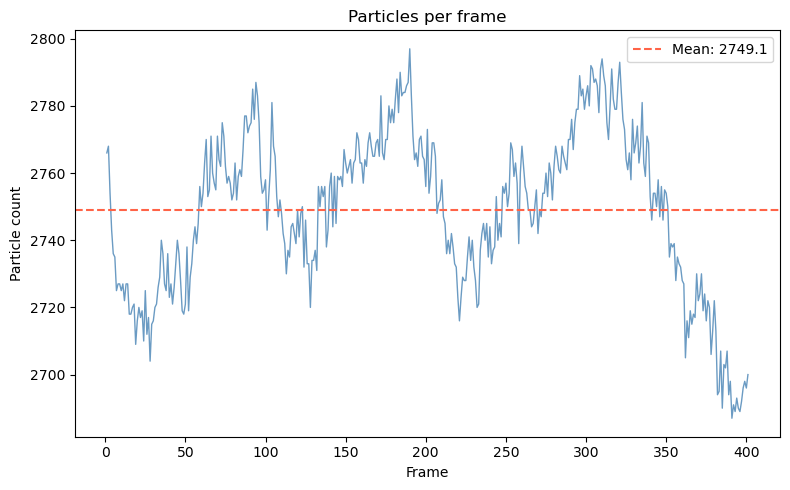

In [38]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))   
# If you have a DataFrame with a 'frame' column
particles_per_frame = df.groupby('frame').size()
ax.plot(particles_per_frame.index, particles_per_frame.values, 
        linewidth=1, color='steelblue', alpha=0.8)
ax.axhline(particles_per_frame.mean(), color='tomato', linestyle='--', 
           linewidth=1.5, label=f'Mean: {particles_per_frame.mean():.1f}')

ax.set_xlabel('Frame')
ax.set_ylabel('Particle count')
ax.set_title('Particles per frame')
ax.legend()

plt.tight_layout()
plt.show()